# 06 · Porównanie metod i liczby uderzeń
**Cel:** porównać kilka ustalonych z góry metod na tych samych płytach. `project.json` wybiera dane.
A: średnia i odchylenie 3 cech rezonansu; B: 26 MFCC, model każdego uderzenia i średnia 3 największych ocen.
Odległość uczy się tylko na OK; klasyfikatory korzystają z OK i NOK. Każda płyta w treningu B ma tę samą łączną wagę.

Priorytetem jest liczba pominiętych NOK i odrzucanych OK. Nie uruchamiamy dziesiątek modeli, żeby wybrać przypadkowo najlepszy.

In [1]:
from pathlib import Path
import os, json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").exists(), "Otwórz cały folder projektu w VS Code."
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))
from pinglab.audio import Config, load_audio, detect_hits, cut_hits, listen
from pinglab.session import load_session
SESSION = load_session(ROOT)
CONFIG, FMAX = SESSION.config, SESSION.fmax
MANIFEST, ANNOTATIONS = SESSION.manifest, SESSION.annotations
print("Dane:", SESSION.source_kind, "· manifest:", MANIFEST.relative_to(ROOT) if MANIFEST.is_relative_to(ROOT) else MANIFEST.name)
print("Wspólne pasmo do", FMAX, "Hz · konfiguracja: project.json")
if SESSION.source_kind == "synthetic":
    display(Markdown("**SYMULACJA — wynik sprawdza narzędzia, nie wykrywanie pęknięć u klienta.**"))


Dane: synthetic · manifest: data/demo/manifest.csv
Wspólne pasmo do 20000.0 Hz · konfiguracja: project.json


**SYMULACJA — wynik sprawdza narzędzia, nie wykrywanie pęknięć u klienta.**

In [2]:
from pinglab.dataset import analyze_manifest
from pinglab.benchmark import benchmark, tap_count_curve
import matplotlib.pyplot as plt
OUT = SESSION.output / 'comparison'
events, quality = analyze_manifest(MANIFEST,OUT,CONFIG,FMAX,
    ANNOTATIONS if ANNOTATIONS.exists() else None)
result = None
if events.empty:
    print('Brak uderzeń; popraw segmentację w 02.')
else:
    try:
        result = benchmark(events)
    except ValueError as error:
        print(error)

## Metryki poza treningiem
Podział: do 5 foldów, rozłączne fizyczne płyty. Skalowanie i model są liczone ponownie w treningu.
Jeśli w treningu jest przynajmniej 5 płyt każdej klasy, wewnętrzna walidacja dobiera próg bez pominięć NOK; zewnętrzny test może nadal mieć przeoczenia. Przy mniejszej próbie próg pozostaje stały.
`average_precision` podsumowuje krzywą precision–recall (nie pole liczone trapezami). Przedziały są opisowe; bootstrap ustalonych prognoz nie obejmuje niepewności treningu.

In [3]:
if result is not None:
    leaderboard,predictions,folds,taps = result
    display(leaderboard.round(3))
    leaderboard.to_json(OUT/'leaderboard.json',orient='records',indent=2)
    predictions.to_csv(OUT/'predictions.csv',index=False)
    (OUT/'folds.json').write_text(json.dumps(folds,indent=2))
    display(predictions.groupby(['method','threshold_policy']).size().rename('płyty'))

,method,n_plates,recall_nok,false_reject,missed_nok,roc_auc,average_precision,recall_cp95,confusion_matrix,recall_bootstrap95,false_reject_bootstrap95
0,A_distance,30,0.9,0.0,1,1.0,1.0,"[0.5549838829718047, 0.9974714214555382]","[[20, 0], [1, 9]]","[0.7, 1.0]","[0.0, 0.0]"
1,A_logistic,30,1.0,0.0,0,1.0,1.0,"[0.6915028921812392, 1.0]","[[20, 0], [0, 10]]","[1.0, 1.0]","[0.0, 0.0]"
2,B_mfcc_top3,30,0.9,0.0,1,1.0,1.0,"[0.5549838829718047, 0.9974714214555382]","[[20, 0], [1, 9]]","[0.7, 1.0]","[0.0, 0.0]"


method       threshold_policy     
A_distance   inner_oof_zero_misses    30
A_logistic   inner_oof_zero_misses    30
B_mfcc_top3  inner_oof_zero_misses    30
Name: płyty, dtype: int64

## Każdy błąd osobno
Wiersze poniżej to płytki pominięte lub niepotrzebnie odrzucone. Wróć do ich odsłuchu i zdjęcia. Nie poprawiaj progu na tych samych testowych błędach i nie przedstawiaj potem wyniku jako niezależnego.

,method,plate_id,label,score,threshold,threshold_policy,fold,predicted,path,plate_type,temperature,photo,notes
0,A_distance,SYN_027,nok,1.189723,1.352588,inner_oof_zero_misses,1,ok,SYN_027_nok.wav,,,,"SYMULACJA, nie ceramika klienta"
1,B_mfcc_top3,SYN_027,nok,0.810203,0.811433,inner_oof_zero_misses,1,ok,SYN_027_nok.wav,,,,"SYMULACJA, nie ceramika klienta"


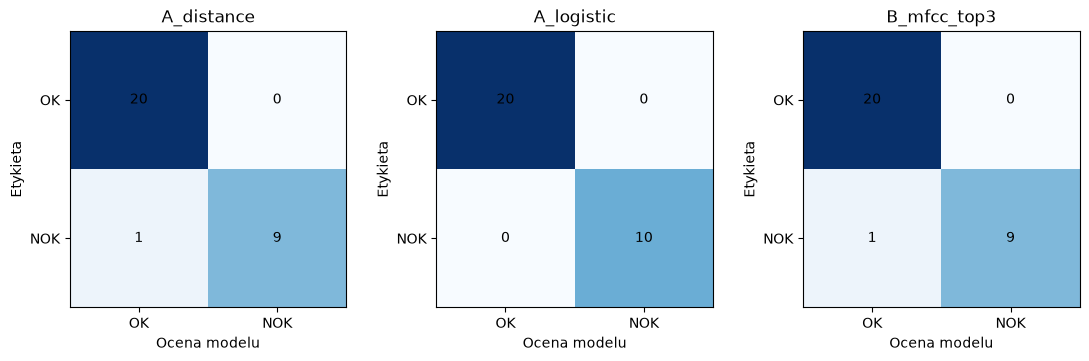

In [4]:
if result is not None:
    marked=predictions.assign(predicted=np.where(predictions.score>=predictions.threshold,'nok','ok'))
    errors=marked[marked.label!=marked.predicted]
    metadata=SESSION.records[['plate_id','path','plate_type','temperature','photo','notes']]
    display(errors.merge(metadata,on='plate_id',how='left'))
    fig,axes=plt.subplots(1,len(leaderboard),figsize=(11,3.5),constrained_layout=True)
    for ax, row in zip(axes,leaderboard.itertuples()):
        cm=np.array(row.confusion_matrix)
        ax.imshow(cm,cmap='Blues')
        for i in range(2):
            for j in range(2): ax.text(j,i,str(cm[i,j]),ha='center',va='center')
        ax.set(title=row.method,xticks=[0,1],xticklabels=['OK','NOK'],yticks=[0,1],yticklabels=['OK','NOK'],xlabel='Ocena modelu',ylabel='Etykieta')
    display(fig); plt.close(fig)

## Ile uderzeń potrzeba?
Dla modelu B losujemy bez zwracania 1/3/5/10 uderzeń, 100 razy. Używamy ocen z modelu, który nie widział tej płyty, i zachowujemy próg dobrany dla pełnego zestawu uderzeń.
Wszystkie k dotyczą tych samych płyt. Pomijamy k większe niż liczba dostępnych uderzeń na najuboższej płycie — demo ma tylko 3.
To wrażliwość na wybór uderzeń przy ustalonym modelu i progu, nie ponowny trening dla każdego k. Rozrzut losowań nie jest przedziałem skuteczności dla populacji.

recall_nok           false_reject          
        mean  min  max         mean  min  max
k                                            
1      0.931  0.9  1.0          0.0  0.0  0.0
3      0.900  0.9  0.9          0.0  0.0  0.0

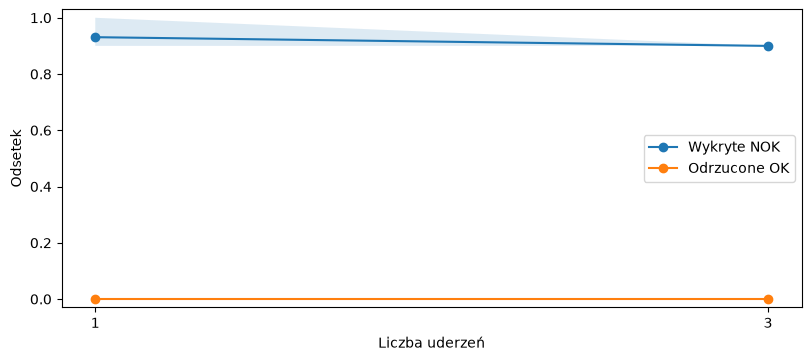

Wyniki zapisane. Dla powtórnych sesji użyj także testu sesji w 03.


In [5]:
if result is not None:
    curve=tap_count_curve(taps,repeats=100)
    curve.to_csv(OUT/'tap_count.csv',index=False)
    if not curve.empty:
        summary=curve.groupby('k')[['recall_nok','false_reject']].agg(['mean','min','max'])
        display(summary.round(3))
        fig,ax=plt.subplots(figsize=(8,3.5),constrained_layout=True)
        for metric,name in [('recall_nok','Wykryte NOK'),('false_reject','Odrzucone OK')]:
            q=curve.groupby('k')[metric]
            ax.plot(q.mean().index,q.mean(),marker='o',label=name)
            ax.fill_between(q.mean().index,q.quantile(.05),q.quantile(.95),alpha=.15)
        ax.set(xlabel='Liczba uderzeń',ylabel='Odsetek',ylim=(-.03,1.03),xticks=summary.index)
        ax.legend(); display(fig); plt.close(fig)
    print('Wyniki zapisane. Dla powtórnych sesji użyj także testu sesji w 03.')

## Co świadomie odkładamy?
AST jest opcjonalnym porównaniem w 04. Pełny trening sieci, rozbudowane strojenie SVM/lasów i SHAP nie są potrzebne do pierwszej oceny wykonalności.
Estymacja tłumienia każdego modu wymaga czystych nagrań i weryfikacji fizycznej — nie nazywamy prostego czasu zaniku pomiarem materiałowym.
**Wynik bez separacji też jest wynikiem PoC.** Najpierw popraw etykiety i protokół, potem dodawaj złożoność.

In [6]:
print('GOTOWE · porównanie metod · źródło:', SESSION.source_kind)

GOTOWE · porównanie metod · źródło: synthetic
